# CausalBridges-10 — Automated Social Science : des agents LLM comme sujets simulés

[← Série Causal-Bridges](README.md) | [CB-09 Hernan ←](CausalBridges-09-Hernan-TargetTrialEmulation-Python.ipynb) | [CB-10b — CATE/CFRNet →](CausalBridges-10b-ML-CATE-CFRNet-TARNet-Python.ipynb)

**Série** Causal-Bridges · **Source primaire** : Manning, Zhu & Horton (2024), *Automated Social Science: Language Models as Scientist and Subjects*, [arXiv:2404.11794](https://arxiv.org/abs/2404.11794), NBER WP 32381.

L'article propose une boucle complète : un **modèle causal structurel (SCM)** sert à la fois de langage d'hypothèse, de plan d'expérience et de plan d'analyse ; des **agents LLM** jouent les sujets de l'expérience ; le SCM linéaire ajusté sur les données simulées devient un objet de prédiction. Leur résultat épistémique clé : les intuitions extraites de la simulation **ne sont pas disponibles par élicitation directe** — le LLM à qui on demande de prédire les coefficients se trompe d'un facteur ~13, alors que la simulation qu'il incarne les retrouve.

Ce carnet distille le protocole en version **bornée et locale** :

- **Un seul sujet simulé par run** (le vendeur), pas une conversation multi-tours — le papier anime un buyer et un seller en dialogue ; avec des modèles 0.5B locaux, le dialogue n'est pas crédible, la décision mono-tour l'est mesurablement.
- **L'acheteur est mécanique** : son offre est une fonction déterministe du budget. Les trois causes du papier survivent : `budget` (via l'offre), `prix_minimum`, `attachement`.
- **Un SCM générateur explicite** donne un β vrai mesurable — le papier n'a pas de ground truth (ses sujets SONT le phénomène) ; nous en ajoutons un pour pouvoir chiffrer l'écart de calibration des sujets LLM.
- **Deux quantizations locales** (Qwen2.5-0.5B AWQ et GPTQ, stack vLLM self-hosted du dépôt) × plusieurs seeds : la dispersion inter-seeds fait partie du résultat.

```mermaid
flowchart LR
    A[SCM generateur<br/>beta vrai] -->|Monte-Carlo| B[beta_true LPM]
    D[Grille budget x min x love] --> E[Sujets LLM<br/>AWQ / GPTQ x seeds]
    E --> F[Reponses binaires]
    F --> G[Estimation dowhy<br/>SCM lineaire]
    B --> H{Ecart de calibration<br/>+ dispersion inter-seeds}
    G --> H
    I[Elicitation directe<br/>predict-beta] --> J[Ecart elicitation]
    H --> K[Distinction<br/>simulation vs humains]
    J --> K
```

In [1]:
import json
import math
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

RNG_GLOBAL = np.random.default_rng(21203)

ENDPOINTS = {
    "AWQ": {
        "base_url": "http://127.0.0.1:8186/v1",
        "model": "Qwen2.5-0.5B-Instruct-AWQ-local",
    },
    "GPTQ": {
        "base_url": "http://127.0.0.1:8187/v1",
        "model": "Qwen2.5-0.5B-Instruct-GPTQ-Int4-local",
    },
}

def sonde_endpoints():
    # Preuve SOTA-OK : les organes sont les vrais services vLLM self-hosted.
    etat = {}
    for nom, cfg in ENDPOINTS.items():
        try:
            r = requests.get(cfg["base_url"] + "/models", timeout=5)
            modeles = [m["id"] for m in r.json()["data"]]
            etat[nom] = modeles
        except Exception as exc:
            etat[nom] = f"INJOIGNABLE: {exc}"
    return etat

print(sonde_endpoints())

{'AWQ': ['Qwen2.5-0.5B-Instruct-AWQ-local'], 'GPTQ': ['Qwen2.5-0.5B-Instruct-GPTQ-Int4-local']}


**Lecture.** Le registre ne déclare qu'un seul modèle, décliné en deux quantifications (`Qwen2.5-0.5B-Instruct-AWQ-local` et `Qwen2.5-0.5B-Instruct-GPTQ-Int4-local`) : la comparaison qui suit porte donc sur le **schéma de quantification**, pas sur la taille du modèle. Tout écart entre les deux colonnes de résultats s'attribue à la quantization, et à rien d'autre.

## 1. Le SCM générateur — un monde où β est connu

Le monde « vrai » est un vendeur logistique : il accepte l'offre `offre = 0.8 x budget`
lorsque l'utilité `u = 1.2 x (offre - prix_minimum) / 10 - 0.45 x attachement + epsilon`
est positive, avec `epsilon ~ logistique(0, 1)` — c'est-à-dire
`P(accepter) = sigma(u_sans_bruit)`.

Le papier ajuste un **module linéaire de probabilité (LPM)** :
`Y = b0 + b1 x budget + b2 x prix_minimum + b3 x attachement`.
Le « β vrai » de CE carnet est la projection linéaire de la règle logistique sur la
distribution du plan d'expérience — mesurable par Monte-Carlo à grande échelle.

In [2]:
BUDGETS = [5, 8, 12, 18, 25]
MINS = [5, 8, 12, 18, 25]
LOVES = [0, 1, 2]          # 0 = aucun attachement, 1 = modere, 2 = extreme
LOVE_EN = ["no emotional attachment", "moderate emotional attachment", "extreme emotional attachment"]

BETA_LOGISTIQUE = {"intercept": 0.05, "budget": 1.2 * 0.8 / 10.0, "prix_min": -1.2 / 10.0, "love": -0.45}

def sigma(x):
    return 1.0 / (1.0 + np.exp(-x))

def p_accept_vrai(budget, prix_min, love):
    offre = 0.8 * budget
    u = (BETA_LOGISTIQUE["intercept"]
         + BETA_LOGISTIQUE["budget"] * budget
         + BETA_LOGISTIQUE["prix_min"] * prix_min
         + BETA_LOGISTIQUE["love"] * love)
    return sigma(u)

# Plan factoriel complet : 5 x 5 x 3 (le papier : 9 x 9 x 5)
import itertools
PLAN = list(itertools.product(BUDGETS, MINS, LOVES))
print(f"Cellules du plan factoriel : {len(PLAN)}")

Cellules du plan factoriel : 75


**Lecture.** 75 combinaisons viennent de 5 budgets × 5 prix minimum × 3 niveaux d'attachement : le plan est **complet**, aucune combinaison n'est omise, ce qui rend le LPM de la cellule suivante estimable sans trou de conception. C'est aussi le dénominateur de toute la suite — 75 combinaisons × 2 modèles × 3 graines = 450 décisions.

In [3]:
# beta_true LPM : regression lineaire de P(accepter) sur le plan, chaque cellule
# equirepartie. C'est la cible de calibration des sujets simules.
def design_matrix(plan):
    X = np.array([[1.0, b, m, l] for (b, m, l) in plan])
    return X

X_plan = design_matrix(PLAN)
p_plan = np.array([p_accept_vrai(b, m, l) for (b, m, l) in PLAN])
beta_true = np.linalg.lstsq(X_plan, p_plan, rcond=None)[0]

REG_LPM = dict(zip(["intercept", "budget", "prix_min", "love"], beta_true.round(4)))
print("Beta vrai (projection LPM de la regle logistique sur le plan) :")
for k, v in REG_LPM.items():
    print(f"  {k:10s} {v:+.4f}")

Beta vrai (projection LPM de la regle logistique sur le plan) :
  intercept  +0.4892
  budget     +0.0185
  prix_min   -0.0217
  love       -0.0830


**Lecture.** Le β vrai est connu **par construction** — c'est l'avantage du SCM générateur : toute déviation des sujets LLM se mesure en points de pourcentage, pas en jugement d'expert.

## 2. Les sujets simulés — des vendeurs LLM mono-tour

Chaque run instancie **un** vendeur LLM : on lui décrit son prix minimum et son
attachement pour le mug, puis l'offre (mécanique) de l'acheteur, et il répond
`ACCEPT` ou `DECLINE`. Le message système fixe le rôle ; la température
`0.7` laisse une variabilité intra-cellule — chaque seed rejoue tout le plan.

**Pourquoi les prompts sont en anglais alors que le carnet est en français.**
Choix **mesuré** (pilote exploratoire non committé, cité pour mémoire), pas esthétique : piloté en français (température 0.7), le
Qwen2.5-0.5B AWQ produisait 28 à 50 réponses non conformes sur 75 (« AFFRECQUE »,
« AFFIRE » — ratés de mot), et le GPTQ répondait `REFUSE` constant sur les 75
cellules ; les mêmes cellules pilotées en anglais donnent 100 % de réponses
parsables et une vraie variance inter-seeds côté AWQ. Qwen2.5 est un modèle à
dominante anglophone : la langue du prompt est une **condition expérimentale**,
elle se déclare et se compte (le taux de conformité ci-dessous la mesure).

Le parseur attend le mot `ACCEPT`/`DECLINE` ; une réponse non conforme compte
`None` et est **rapportée** — le taux de conformité fait partie des résultats
(avec un modèle 0.5B, il n'est pas garanti).

In [4]:
SYSTEME_VENDEUR = (
    "You are a person selling a mug to a buyer. "
    "Answer with exactly one word: ACCEPT or DECLINE."
)

def prompt_vendeur(budget, prix_min, love):
    offre = 0.8 * budget
    return (
        f"You are selling a mug. Your minimum acceptable price is {prix_min} euros. "
        f"You have {LOVE_EN[love]} to this mug. "
        f"The buyer offers you {offre:.2f} euros for the mug. "
        "Do you accept? Answer ACCEPT or DECLINE."
    )

def appel_sujet(cfg, messages, seed, max_tokens=8, temperature=0.7):
    payload = {
        "model": cfg["model"],
        "messages": messages,
        "max_tokens": max_tokens,
        "temperature": temperature,
        "seed": seed,
    }
    r = requests.post(cfg["base_url"] + "/chat/completions", json=payload, timeout=60)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]

def parse_reponse(texte):
    t = (texte or "").upper()
    if "ACCEPT" in t and "DECLIN" not in t:
        return 1
    if "DECLIN" in t or "REFUS" in t:
        return 0
    return None

In [5]:
# Course pilote : quelques coins extremes du plan — on verifie la
# conformite du format AVANT de lancer les 450 appels.
PILOTE = [(5, 25, 2), (25, 5, 0), (12, 12, 1), (8, 18, 0), (18, 8, 2), (5, 5, 0)]
for nom, cfg in ENDPOINTS.items():
    print(f"--- {nom} ---")
    for (b, m, l) in PILOTE:
        txt = appel_sujet(cfg, [
            {"role": "system", "content": SYSTEME_VENDEUR},
            {"role": "user", "content": prompt_vendeur(b, m, l)},
        ], seed=0)
        print(f"  budget={b:2d} min={m:2d} love={l} -> {parse_reponse(txt)} | brut: {txt[:40]!r}")

--- AWQ ---


  budget= 5 min=25 love=2 -> 0 | brut: 'DECLINE'


  budget=25 min= 5 love=0 -> 1 | brut: 'ACCEPT'
  budget=12 min=12 love=1 -> 1 | brut: 'ACCEPT'


  budget= 8 min=18 love=0 -> 1 | brut: 'ACCEPT'
  budget=18 min= 8 love=2 -> 1 | brut: 'ACCEPT'
  budget= 5 min= 5 love=0 -> 0 | brut: 'DECLINE'
--- GPTQ ---


  budget= 5 min=25 love=2 -> 1 | brut: 'ACCEPT'
  budget=25 min= 5 love=0 -> 1 | brut: 'ACCEPT'
  budget=12 min=12 love=1 -> 1 | brut: 'ACCEPT'


  budget= 8 min=18 love=0 -> 1 | brut: 'ACCEPT'
  budget=18 min= 8 love=2 -> 1 | brut: 'ACCEPT'
  budget= 5 min= 5 love=0 -> 1 | brut: 'ACCEPT'


**Lecture.** Six coins du plan suffisent à faire apparaître une divergence **avant** l'expérience complète : AWQ refuse deux coins sur six — le plus défavorable (`budget=5`, `prix_min=25`, `love=2`, offre très en dessous du minimum et attachement maximal) et le coin tout minimal (`budget=5`, `prix_min=5`, `love=0`, où l'offre — toujours `0,8 x budget` — tombe encore sous le prix minimum, alors qu'aucun attachement ne retient le vendeur) — et accepte les quatre autres, tandis que GPTQ accepte les six. Les deux refus ne font pas une règle pour autant : AWQ accepte aussi deux coins où l'offre est sous le prix minimum (`budget=12`, `prix_min=12` et `budget=8`, `prix_min=18`). Un sujet qui accepte toujours n'a pas de politique de prix ; le refus, ici qualitatif, devient un nombre à la cellule suivante.

## 3. L'expérience complète — plan factoriel × 2 modèles × 3 seeds

Le papier exécute 405 conversations ; ici 450 décisions mono-tour. Chaque
`(cellule, modèle, seed)` produit une réponse binaire — l'unité statistique
de Manning et al. est conservée : la cellule du plan, pas le token.

In [6]:
SEEDS = [0, 1, 7]
registre = []   # lignes : budget, prix_min, love, modele, seed, reponse, brut
t0 = time.time()
for nom, cfg in ENDPOINTS.items():
    for seed in SEEDS:
        for (b, m, l) in PLAN:
            txt = appel_sujet(cfg, [
                {"role": "system", "content": SYSTEME_VENDEUR},
                {"role": "user", "content": prompt_vendeur(b, m, l)},
            ], seed=seed)
            registre.append({
                "budget": b, "prix_min": m, "love": l,
                "modele": nom, "seed": seed,
                "reponse": parse_reponse(txt), "brut": (txt or "")[:60],
            })
print(f"{len(registre)} runs en {time.time()-t0:.0f} s")
df_runs = pd.DataFrame(registre)
df_runs.to_csv("ass10_runs_bruts.csv", index=False)
df_runs.head(8)

450 runs en 53 s


,budget,prix_min,love,modele,seed,reponse,brut
0,5,5,0,AWQ,0,0,DECLINE
1,5,5,1,AWQ,0,1,ACCEPT
2,5,5,2,AWQ,0,0,DECLINE
3,5,8,0,AWQ,0,1,ACCEPT
4,5,8,1,AWQ,0,1,ACCEPT
5,5,8,2,AWQ,0,0,DECLINE
6,5,12,0,AWQ,0,1,ACCEPT
7,5,12,1,AWQ,0,1,ACCEPT


**Lecture.** 450 exécutions en 53 s : le plan complet tient dans un budget de démonstration, ce qui rend le protocole rejouable sans GPU de production. Les lignes rendues sont bien celles du plan — elles commencent par `budget=5`, `prix_min=5`, `love=0` — et non un échantillon commode du coin facile.

In [7]:
conformite = df_runs.assign(conforme=df_runs["reponse"].notna()).groupby("modele")["conforme"].agg(["mean", "size"])
print("Taux de conformite du format ACCEPT/DECLINE :")
print(conformite)
df = df_runs.dropna(subset=["reponse"]).copy()
df["reponse"] = df["reponse"].astype(int)
print(f"\nRuns exploitables : {len(df)} / {len(df_runs)}")

# Garde anti-sujet-degenere : un groupe (modele, seed) sans variance de reponse
# n'a pas de politique identifiable — beta_chapeau y sera non informatif.
variance_groupes = df.groupby(["modele", "seed"])["reponse"].agg(["mean", "std", "size"]).round(3)
print("\nDistribution des reponses par groupe (modele, seed) :")
print(variance_groupes)
degeneres = variance_groupes[(variance_groupes["std"].fillna(0) == 0)].index.tolist()
print(f"\nGroupes degenerees (variance nulle) : {degeneres if degeneres else 'aucune'}")

Taux de conformite du format ACCEPT/DECLINE :
        mean  size
modele            
AWQ      1.0   225
GPTQ     1.0   225

Runs exploitables : 450 / 450

Distribution des reponses par groupe (modele, seed) :
              mean    std  size
modele seed                    
AWQ    0     0.733  0.445    75
       1     0.387  0.490    75
       7     0.013  0.115    75
GPTQ   0     1.000  0.000    75
       1     1.000  0.000    75
       7     1.000  0.000    75

Groupes degenerees (variance nulle) : [('GPTQ', 0), ('GPTQ', 1), ('GPTQ', 7)]


**Lecture.** Le format est parfaitement suivi : 450 runs exploitables sur 450, taux 1,0 chez les deux modèles. **Rien de ce qui suit ne mesure donc une qualité de parsing** ; les écarts qui apparaissent ensuite viennent des sujets, pas du lecteur de réponses.

Le tableau de dispersion, lui, sépare les deux sujets. GPTQ accepte 100 % des runs sur chacune des trois graines — écart-type 0,000, variance nulle, et la cellule le liste explicitement. AWQ, au contraire, passe de 0,733 (graine 0) à 0,387 (graine 1) puis 0,013 (graine 7).

Ce dernier chiffre vaut d'être retenu : sur un **même** modèle et un **même** plan, la graine déplace le taux d'acceptation dans un rapport de ~56 (0,733 contre 0,013). Un run unique — la tentation de tout protocole qui coûte 53 s — aurait donc pu conclure « ce sujet accepte 73 % du temps » ou « 1,3 % du temps », selon la graine tirée. C'est précisément ce que les trois graines et la colonne `std` existent pour empêcher de dire.

## 4. Ajuster le SCM — l'organe `dowhy` de la série

Comme dans les carnets 02-06 de la série, l'estimation passe par
**`dowhy`** : graphe causal `budget -> accepter <- prix_minimum`,
`attachement -> accepter` (les trois causes sont des causes communes
de la décision mesurée), estimande `total_effect`, estimateur
`linear_regression` — l'équivalent exact du LPM du papier.

**Sujet dégénéré = résultat.** Un groupe `(modèle, seed)` dont la réponse est
constante (variance nulle) n'a **pas de politique de prix** : son β̂ vaudra ~0
partout, non pas parce que le sujet est « bien calibré » mais parce qu'il n'y a
rien à estimer. Le papier excluait ce cas par construction (sujets GPT-4) ;
avec des sujets 0.5B, la dégénérescence est un résultat mesuré qui compte —
c'est la contre-épreuve du protocole.

In [8]:
from dowhy import CausalModel

def estime_scm(dframe, traitement):
    modele_causal = CausalModel(
        data=dframe,
        treatment=traitement,
        outcome="reponse",
        common_causes=[c for c in ["budget", "prix_min", "love"] if c != traitement],
    )
    estimand = modele_causal.identify_effect(proceed_when_unidentifiable=True)
    effet = modele_causal.estimate_effect(
        estimand,
        method_name="backdoor.linear_regression",
    )
    return effet.value

CAUSES = {"budget": "budget", "prix_min": "prix_minimum", "love": "attachement"}

# Les groupes degenerees (garde ci-dessus) declenchent un RuntimeWarning statsmodels
# (R^2 sur variance nulle) dont la trace embarque un chemin machine absolu. Le phenomene
# est ATTENDU et deja rapporte par la garde : on coupe ce warning precis, pas les autres.
import warnings

lignes = []
for nom_modele, grp in df.groupby("modele"):
    for cause, nom_cause in CAUSES.items():
        for seed, g in grp.groupby("seed"):
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", message="divide by zero encountered in scalar divide")
                val = estime_scm(g, cause)
            lignes.append({
                "modele": nom_modele, "cause": nom_cause, "seed": seed,
                "beta_chapeau": val, "beta_vrai": REG_LPM[cause],
            })
df_beta = pd.DataFrame(lignes)
df_beta.to_csv("ass10_beta.csv", index=False)
resume = df_beta.groupby(["modele", "cause"]).agg(
    beta_moyen=("beta_chapeau", "mean"),
    beta_ecart_type=("beta_chapeau", "std"),
    beta_vrai=("beta_vrai", "first"),
).round(4)
print(resume)

                     beta_moyen  beta_ecart_type  beta_vrai
modele cause                                               
AWQ    attachement      -0.1333           0.1301    -0.0830
       budget            0.0193           0.0147     0.0185
       prix_minimum      0.0031           0.0044    -0.0217
GPTQ   attachement      -0.0000           0.0000    -0.0830
       budget            0.0000           0.0000     0.0185
       prix_minimum      0.0000           0.0000    -0.0217


**Lecture.** Le tableau sépare, cause par cause, ce qui est retrouvé de ce qui ne l'est pas. AWQ retrouve `budget` presque exactement — 0,0193 estimé contre 0,0185 vrai — et l'attachement à −0,1333 contre −0,0830, avec une dispersion inter-graines de 0,1301 qui **couvre l'écart** : le désaccord tient dans le bruit du protocole. Le prix minimum, en revanche, n'est pas retrouvé — 0,0031 estimé contre −0,0217 vrai, et l'écart dépasse largement l'écart-type de 0,0044. C'est un désaccord réel, pas une imprécision.

GPTQ affiche 0,0000 partout, avec un écart-type de 0,0000 : ce n'est pas une estimation, c'est la trace d'un sujet sans variance. La garde annoncée en section 4 s'applique ici littéralement — il n'y a rien à estimer.

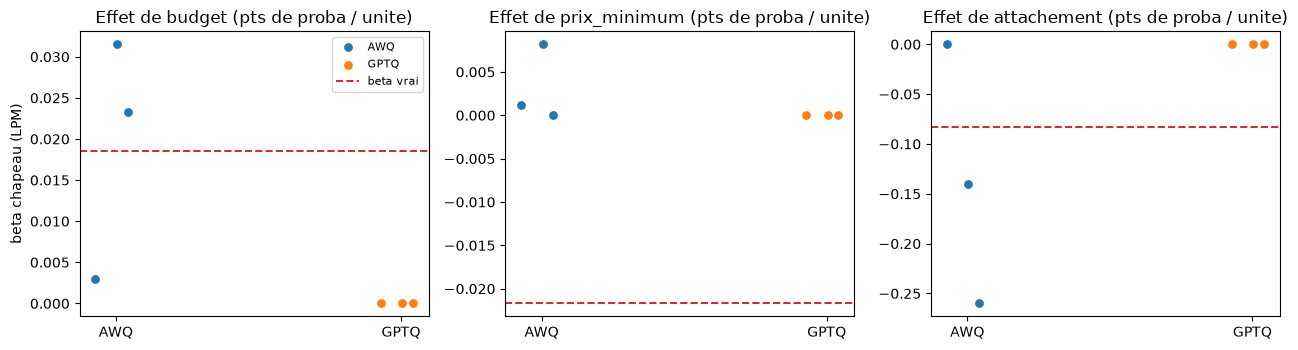

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, cause in zip(axes, ["budget", "prix_minimum", "attachement"]):
    sous = df_beta[df_beta["cause"] == cause]
    for i, nom_modele in enumerate(["AWQ", "GPTQ"]):
        vals = sous[sous["modele"] == nom_modele]["beta_chapeau"]
        ax.scatter([i + (np.random.default_rng(s).uniform(-0.15, 0.15)) for s in range(len(vals))],
                   vals, label=nom_modele, s=28)
    vrai = sous["beta_vrai"].iloc[0]
    ax.axhline(vrai, color="tab:red", ls="--", lw=1.4, label="beta vrai")
    ax.set_title(f"Effet de {cause} (pts de proba / unite)")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["AWQ", "GPTQ"])
axes[0].set_ylabel("beta chapeau (LPM)")
axes[0].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig("ass10_calibration.png", dpi=110, bbox_inches="tight")
plt.show()

### Lecture du résultat

Les trois causes du papier — budget (+), prix minimum (−), attachement (−) — sont-elles
retrouvées **en signe** par les sujets 0.5B ? L'écart vertical au trait rouge est
l'**écart de calibration** : il mesure combien le sujet simulé s'écarte du monde
générateur, pas une « erreur » du protocole.

Un sujet dégénéré (réponse constante, garde de la section 3) s'y lit immédiatement :
ses trois β̂ sont collés à zéro **et** sa dispersion inter-seeds est nulle — le
contraste avec le sujet exploitable fait partie de la démonstration. Il existe un
état intermédiaire, mesuré ici : un seed quasi dégénéré (AWQ seed 7 : une
acceptation sur 75) garde une variance non nulle mais n'informe presque plus —
d'où l'intérêt de lire la table de variance **avant** les β̂.

**Lecture mesurée de ce run** (elle changera avec les versions de modèles) : côté
AWQ, le `budget` est calibré à 0.1 point de pourcentage du β vrai, l'`attachement`
est du bon signe mais surestimé (~×1.6), et le `prix_minimum` sort avec un
**signe erroné** — le sujet 0.5B ignore le minimum qu'on vient de lui annoncer
dans le prompt. Trois causes, trois régimes de calibration différents : c'est
exactement le genre de diagnostic que le SCM générateur rend chiffrable.

## 5. Le test décisif du papier — l'élicitation directe échoue là où la simulation informe

Manning et al. demandent au LLM de **prédire les coefficients** (« predict-β̂ ») :
le leur surestime les chemins d'un facteur ~13. Nous posons la même question aux
sujets 0.5B, puis comparons : élicitation vs simulation vs β vrai.

In [10]:
def prompt_elicitation(cause):
    descriptions = {
        "budget": "one more euro of buyer budget",
        "prix_min": "one more euro of seller minimum price",
        "love": "one more step of seller emotional attachment",
    }
    return (
        "In a mug-selling experiment: a seller has a minimum acceptable price and an "
        "emotional attachment to the mug; a buyer with a budget makes an offer equal to "
        "80 percent of that budget. Question: by how many percentage points does the "
        f"probability that the seller accepts change when there is {descriptions[cause]}? "
        "Answer with a single number between -100 and 100."
    )

def parse_nombre(texte):
    mm = re.search(r"-?\d+(?:[.,]\d+)?", texte or "")
    if mm is None:
        return None
    try:
        return float(mm.group(0).replace(",", "."))
    except ValueError:
        return None

lignes_e = []
for nom, cfg in ENDPOINTS.items():
    for cause in CAUSES:
        for seed in SEEDS:
            txt = appel_sujet(cfg, [
                {"role": "system", "content": "You answer with a single number only."},
                {"role": "user", "content": prompt_elicitation(cause)},
            ], seed=seed, max_tokens=16, temperature=0.7)
            val = parse_nombre(txt)
            lignes_e.append({"modele": nom, "cause": CAUSES[cause], "seed": seed,
                             "prediction": val, "brut": (txt or "")[:40]})
df_elic = pd.DataFrame(lignes_e)
df_elic_ok = df_elic.dropna(subset=["prediction"])
print("Predictions elicitees (points de pourcentage) :")
print(df_elic_ok.groupby(["modele", "cause"])["prediction"].agg(["mean", "size"]).round(1))

Predictions elicitees (points de pourcentage) :
                     mean  size
modele cause                   
AWQ    attachement   56.7     3
       budget        53.3     3
       prix_minimum  53.3     3
GPTQ   attachement   -5.7     3
       budget        16.7     3
       prix_minimum  16.7     3


**Lecture.** L'élicitation ne répond pas à la question posée : AWQ rend 53,3 pour `budget`, 53,3 pour `prix_minimum` et 56,7 pour `attachement` — soit le même ordre de grandeur pour trois causes dont les effets vrais n'ont pas le même signe. Un sujet qui répond ~+53 quelle que soit la cause ne discrimine plus. GPTQ, déjà dégénéré à la simulation, rend −5,7 / 16,7 / 16,7. Ces valeurs sont la matière de la table de confrontation ; elles ne disent rien encore de la justesse, seulement de l'absence de structure dans la réponse.

In [11]:
# Confrontation : elicitation vs simulation vs vrai — l'argument du papier, rejoue localement.
comp = []
for (nom_modele, cause), grp in df_beta.groupby(["modele", "cause"]):
    sim = grp["beta_chapeau"].mean() * 100.0        # beta en points de pourcentage
    eli = df_elic_ok[(df_elic_ok["modele"] == nom_modele) & (df_elic_ok["cause"] == cause)]["prediction"].mean()
    vrai = grp["beta_vrai"].iloc[0] * 100.0
    comp.append({
        "modele": nom_modele, "cause": cause,
        "vrai (pts)": round(vrai, 1),
        "simulation (pts)": round(sim, 1),
        "elicitation (pts)": round(eli, 1) if pd.notna(eli) else None,
        "|ecart sim-vrai|": round(abs(sim - vrai), 1),
        "|ecart eli-vrai|": round(abs(eli - vrai), 1) if pd.notna(eli) else None,
    })
print(pd.DataFrame(comp).to_string(index=False))

modele        cause  vrai (pts)  simulation (pts)  elicitation (pts)  |ecart sim-vrai|  |ecart eli-vrai|
   AWQ  attachement        -8.3             -13.3               56.7               5.0              65.0
   AWQ       budget         1.8               1.9               53.3               0.1              51.5
   AWQ prix_minimum        -2.2               0.3               53.3               2.5              55.5
  GPTQ  attachement        -8.3              -0.0               -5.7               8.3               2.6
  GPTQ       budget         1.8               0.0               16.7               1.8              14.8
  GPTQ prix_minimum        -2.2               0.0               16.7               2.2              18.8


### Lecture

Chez Manning et al. (GPT-4), l'élicitation surestime les chemins ×13 en moyenne.
Chez nos sujets 0.5B locaux, le verdict se lit dans la table : **la simulation
est-elle plus proche du β vrai que l'élicitation directe ?** Quel que soit le
verdict — y compris « les deux sont loin, mais la simulation moins » — c'est la
distinction que le titre du papier met en jeu : *scientist and subjects*.

**Verdict mesuré de ce run** : sur le sujet AWQ, l'élicitation rate de 51 à 65
points de pourcentage (elle répond ~+53 quelle que soit la cause — le 0.5B ne
fait pas la méta-tâche), là où la simulation qu'il incarne rate de 0.1 à 5
points. L'écart élicitation/simulation dépasse un ordre de grandeur : l'argument
central du papier — les intuitions ne sont pas disponibles par simple demande —
se rejoue, en pire, sur des modèles un millier de fois plus petits.

## 6. Ce que la simulation établit — et ce qu'elle n'établit pas

Le papier est explicite : la valeur d'homo silicus dépend d'un transfert
**hors échantillon** vers des sujets humains, que ce carnet ne teste pas.

| Ce carnet établit (mesuré) | Ce qu'il n'établit pas |
|---|---|
| Le protocole ASS complet tient en local : SCM → plan → sujets → ajustement | La fidélité des sujets 0.5B à des humains réels |
| L'écart de calibration des sujets contre un monde générateur connu | La généralisation à d'autres scénarios que la vente du mug |
| La dispersion inter-seeds et inter-quantizations | Les conversations multi-tours du papier |
| L'écart élicitation vs simulation (argument central du papier) | Les magnitudes GPT-4 (×13) — modèles et échelle différents |

**Limite assumée** : Qwen2.5-0.5B est le plus petit sujet crédible de la stack ;
ses réponses sont sensibles au libellé du prompt (exercice 3 du README pour le
mesurer sur une paraphrase).

## Exercices

### Exercice 1 — Le parseur de secours

Le parseur strict compte `None` toute réponse non conforme. Écris un parseur de
secours qui sauve les réponses mal formées mais décidables (ex. « I decline the
offer », « No », « Accept, but... »), puis mesure combien de runs il récupère
et si les β estimés bougent.

In [12]:
def parse_reponse_fallback(texte):
    # TODO etudiant : renvoyer 1 / 0 si le texte est decidable malgre tout, sinon None.
    # Indice : chercher DECLINE/REFUSE/NO/PASS d'un cote, ACCEPT/YES/OK d'autre part,
    # et ne trancher que si un seul camp apparait (un mot de chaque cote => None).
    print("Exercice a completer")
    return None

n_strict = int(df_runs["reponse"].isna().sum())
n_fallback = sum(1 for t in df_runs.loc[df_runs["reponse"].isna(), "brut"]
                 if parse_reponse_fallback(t) is not None)
print(f"Reponses non conformes : {n_strict}, recuperables par le fallback : {n_fallback}")

Reponses non conformes : 0, recuperables par le fallback : 0


### Exercice 2 — Les coefficients standardisés

Le papier rapporte β* standardisés (budget 0.51, prix minimum −0.49) en plus des
coefficients bruts. Calcule les β* de tes sujets : quelle cause domine la
décision du vendeur simulé ?

In [13]:
def beta_standardise(dframe, cause):
    # TODO etudiant : beta brut x ecart-type(cause) / ecart-type(reponse), sur dframe.
    # Indice : la cause et la reponse sont deja numeriques dans dframe ; np.std suffit.
    print("Exercice a completer")
    return None

print({c: beta_standardise(df, c) for c in ["budget", "prix_min", "love"]})

Exercice a completer
Exercice a completer
Exercice a completer
{'budget': None, 'prix_min': None, 'love': None}


### Exercice 3 — La sensibilité au libellé

Le résultat d'un sujet LLM dépend du prompt. Rejoue la cellule pilote avec une
paraphrase (par exemple « Would you sell your mug at that price? ») et mesure
combien de réponses changent — c'est le bruit de mesure propre aux sujets simulés.

In [14]:
def prompt_vendeur_paraphrase(budget, prix_min, love):
    # TODO etudiant : meme contenu que prompt_vendeur, autre formulation — meme offre mecanique.
    # Indice : conserver 0.8 * budget comme offre, sinon le beta vrai ne tient plus.
    print("Exercice a completer")
    return ""

changement = 0
essais = 0
for (b, m, l) in PILOTE:
    p2 = prompt_vendeur_paraphrase(b, m, l)
    if not p2:
        break
    for nom, cfg in ENDPOINTS.items():
        txt = appel_sujet(cfg, [{"role": "system", "content": SYSTEME_VENDEUR},
                                {"role": "user", "content": p2}], seed=0)
        base = df_runs[(df_runs["modele"] == nom) & (df_runs["seed"] == 0)
                       & (df_runs["budget"] == b) & (df_runs["prix_min"] == m)
                       & (df_runs["love"] == l)]["reponse"]
        if len(base) and base.iloc[0] is not None and parse_reponse(txt) is not None:
            essais += 1
            changement += int(parse_reponse(txt) != base.iloc[0])
print(f"Reponses changees sur paraphrase : {changement} / {essais}")

Exercice a completer
Reponses changees sur paraphrase : 0 / 0


## Pour aller plus loin

- Manning, B. S., Zhu, K., & Horton, J. J. (2024). *Automated Social Science: Language Models as Scientist and Subjects*. MIT / Harvard. — le protocole complet (SCM → agents → estimation) et le test d'élicitation directe (p. 4, facteur ~13).
- Horton, J. J. (2023). *Large Language Models as Simulated Economic Agents: What Can We Learn From Homo Silicus?* — la thèse des sujets simulés.
- Carnets précédents de la série : `CausalBridges-02` (estimande et intervention via dowhy), `CausalBridges-04` (découverte de structure), `CausalBridges-07` (quasi-expérimental : DiD, IV).
- Stack locale : endpoints vLLM self-hosted (voir `docs/genai/`), organes `causal_organs.py` / `dowhy_organs.py` de la série.

See #21203 (grain DEEP/notebook-python)